In [71]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

import torch 
import torch.nn as nn 
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
random_state = 42
np.random.seed(random_state)
torch.manual_seed(random_state)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(random_state)

In [72]:
training_data = datasets.FashionMNIST(
    root = 'data',
    train = True,
    download = True,
    transform = ToTensor()
)
test_data = datasets.FashionMNIST(
    root = 'data',
    train = False,
    download = True,
    transform = ToTensor()
)
train_dataloader = DataLoader(training_data, batch_size = 1024, shuffle = True)
test_dataloader = DataLoader(test_data, batch_size = 1024)

In [73]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(784, 128)
        self.linear2 = nn.Linear(128, 128)
        self.output = nn.Linear(128, 10)
    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        out = self.output(x)
        return out.squeeze(1)
model = NeuralNetwork().to(device)
learning_rate = 0.01
epochs = 10
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)

In [74]:
def train(dataloader, model, loss_function, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        y_pred = model(X)

        loss = loss_function(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X.size(0)
        correct += (y_pred.argmax(dim = 1) == y).sum().item()
        total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy


In [75]:
def test(dataloader, model, loss_function, optimizer):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            loss = loss_function(y_pred, y)
            total_loss += loss.item() * X.size(0)
            correct += (y_pred.argmax(dim = 1) == y).sum().item()
            total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy

In [76]:
# Training
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies =[]

for epoch in range(epochs):
    train_loss, train_acc = train(train_dataloader, model, loss_function, optimizer)

    test_loss, test_acc = test(test_dataloader, model, loss_function, optimizer)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    print(
        f"Epoch [{epoch + 1} / {epochs}] |"
        f"Train Loss: {train_loss:.4f} |"
        f"Train Acc: {train_acc:.2f} % |"
        f"Test Loss: {test_loss:.4f} |"
        f"Test Acc: {test_acc:.4f} %"

    )
print("Training complete!")

Epoch [1 / 10] |Train Loss: 2.2767 |Train Acc: 14.62 % |Test Loss: 2.2499 |Test Acc: 14.3600 %
Epoch [2 / 10] |Train Loss: 2.2187 |Train Acc: 18.50 % |Test Loss: 2.1811 |Test Acc: 24.5000 %
Epoch [3 / 10] |Train Loss: 2.1307 |Train Acc: 32.58 % |Test Loss: 2.0700 |Test Acc: 40.0700 %
Epoch [4 / 10] |Train Loss: 1.9891 |Train Acc: 47.33 % |Test Loss: 1.8963 |Test Acc: 50.3800 %
Epoch [5 / 10] |Train Loss: 1.7902 |Train Acc: 50.86 % |Test Loss: 1.6830 |Test Acc: 51.1000 %
Epoch [6 / 10] |Train Loss: 1.5817 |Train Acc: 53.83 % |Test Loss: 1.4899 |Test Acc: 56.6600 %
Epoch [7 / 10] |Train Loss: 1.4077 |Train Acc: 58.43 % |Test Loss: 1.3388 |Test Acc: 58.5900 %
Epoch [8 / 10] |Train Loss: 1.2736 |Train Acc: 60.37 % |Test Loss: 1.2233 |Test Acc: 60.8400 %
Epoch [9 / 10] |Train Loss: 1.1703 |Train Acc: 62.01 % |Test Loss: 1.1338 |Test Acc: 62.6700 %
Epoch [10 / 10] |Train Loss: 1.0894 |Train Acc: 63.44 % |Test Loss: 1.0629 |Test Acc: 63.3700 %
Training complete!


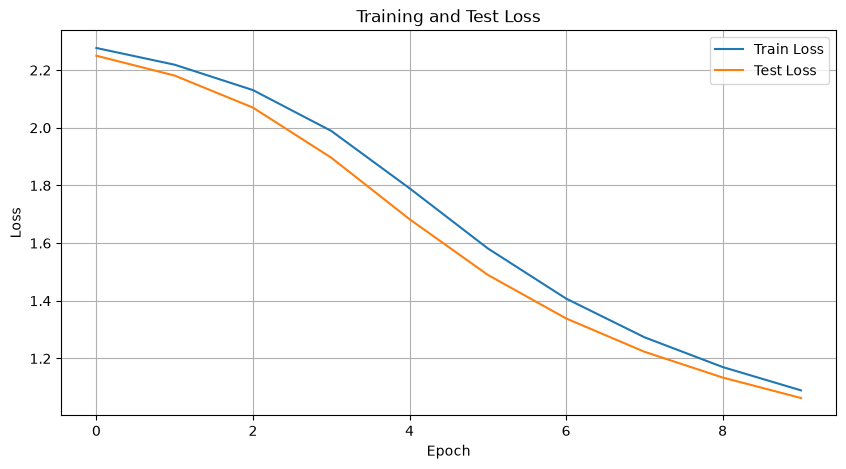

In [77]:
plt.figure(figsize = (10, 5))
plt.plot(train_losses, label = 'Train Loss')
plt.plot(test_losses, label = "Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True)
plt.show()

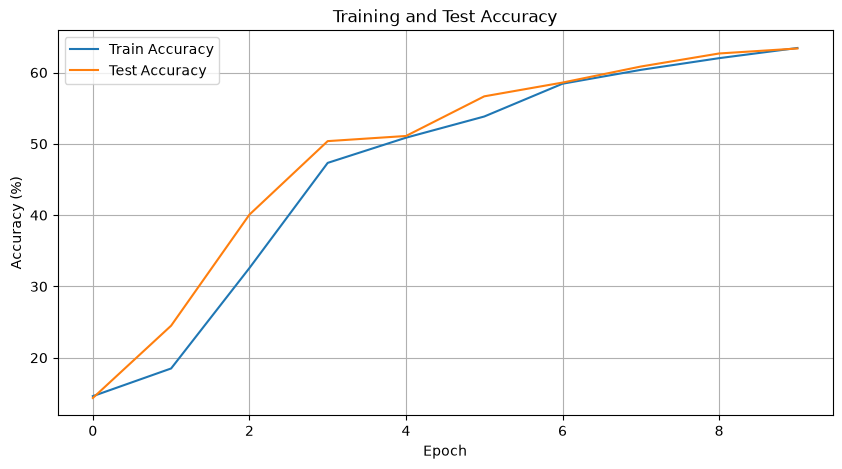

In [78]:
plt.figure(figsize = (10, 5))

plt.plot(train_accuracies, label = 'Train Accuracy')
plt.plot(test_accuracies, label = 'Test Accuracy')
plt.xlabel("Epoch")
plt.ylabel('Accuracy (%)')
plt.title("Training and Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()